# 1 - Data Generation

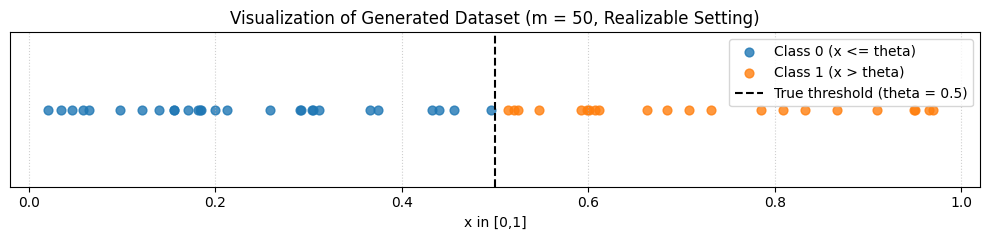

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
theta_true=0.5
sample_sizes=[5,10,20,50,100,200]

def generate_data(m,theta=theta_true,noise_rate=0.0):
  X=np.random.uniform(0.0,1.0,size=m)
  y=(X>theta).astype(int)
  if noise_rate>0.0:
    flip_mask=np.random.binomial(1,noise_rate,size=m).astype(bool)
    y[flip_mask]=1-y[flip_mask]
  return X,y

X_vis,y_vis=generate_data(50,theta=theta_true,noise_rate=0.0)

plt.figure(figsize=(10,2.5))
plt.scatter(X_vis[y_vis==0],np.zeros_like(X_vis[y_vis==0]),color='tab:blue',label='Class 0 (x <= theta)',alpha=0.8,s=40)
plt.scatter(X_vis[y_vis==1],np.zeros_like(X_vis[y_vis==1]),color='tab:orange',label='Class 1 (x > theta)',alpha=0.8,s=40)
plt.axvline(x=theta_true,color='black',linestyle='--',linewidth=1.5,label=f'True threshold (theta = {theta_true})')
plt.title('Visualization of Generated Dataset (m = 50, Realizable Setting)')
plt.xlabel('x in [0,1]')
plt.yticks([])
plt.xlim(-0.02,1.02)
plt.legend(loc='upper right')
plt.grid(axis='x',linestyle=':',alpha=0.6)
plt.tight_layout()
plt.show()

# 2 - Implementation of ERM

In [3]:
def compute_empirical_error(threshold,X,y):
  preds=(X>threshold).astype(int)
  return np.mean(preds!=y)

def train_erm_threshold(X,y):
  X_sorted=np.sort(X)
  midpoints=(X_sorted[:-1]+X_sorted[1:])/2.0
  candidates=np.concatenate(([0.0],midpoints,[1.0]))
  best_threshold=candidates[0]
  min_error=1.0
  for t in candidates:
    err=compute_empirical_error(t,X,y)
    if err<min_error:
      min_error=err
      best_threshold=t
  return best_threshold,min_error

### ERM Strategy Explanation

The hypothesis class considered is $\mathcal{H}=\{h_t(x)=\mathbf{1}_{x>t}\mid t\in[0,1]\}$. Although the parameter space is infinite, the empirical classification of a finite training sample $S=\{(x_i,y_i)\}_{i=1}^m$ only changes when the threshold $t$ crosses one of the observed sample points.

*To determine an empircal risk minimizer:*

1.   We sort the training inputs in ascending order: $x_{(1)}\le x_{(2)}\le\dots\le x_{(m)}$.
2.   Over each open interval $(x_{(i)},x_{(i+1)})$, the predictions-and hence the empirical error-remain constant. Therefore, evaluating the midpoints $\frac{x_{(i)}+x_{(i+1)}}{2}$ for all $i\in\{1,\dots,m-1\}$ is sufficient to explore all non-equivalent classification behaviors.
3.  We also test the boundary values $0.0$ and $1.0$ (corresponding to predicting all $1$s or all $0$s).
4.  For each candidate threshold $t$, we compute the empirical risk $L_S(h_t)=\frac{1}{m}\sum_{i=1}^m\mathbf{1}_{h_t(x_i)\neq y_i}$ and select a threshold $t^*$ achieving the minimal empirical error.



# 3 - Performance Evaluation



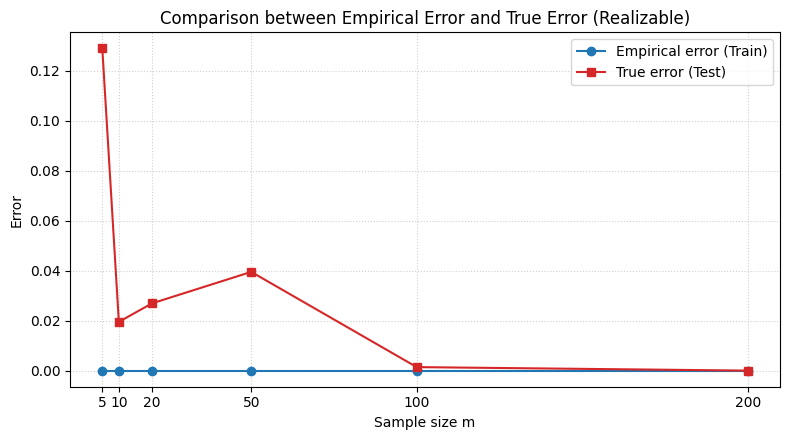

In [7]:
n_test=10000
X_test,y_test=generate_data(n_test,theta=theta_true,noise_rate=0.0)

empirical_errors=[]
true_errors=[]

for m in sample_sizes:
  X_train,y_train=generate_data(m,theta=theta_true,noise_rate=0.0)
  t_opt,emp_err=train_erm_threshold(X_train,y_train)
  test_err=compute_empirical_error(t_opt,X_test,y_test)
  empirical_errors.append(emp_err)
  true_errors.append(test_err)

plt.figure(figsize=(8,4.5))
plt.plot(sample_sizes,empirical_errors,marker='o',label='Empirical error (Train)',color='tab:blue')
plt.plot(sample_sizes,true_errors,marker='s',label='True error (Test)',color='tab:red')
plt.title('Comparison between Empirical Error and True Error (Realizable)')
plt.xlabel('Sample size m')
plt.ylabel('Error')
plt.xticks(sample_sizes)
plt.grid(True,linestyle=':',alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

### Performance Evaluation Interpretation (Realizable Setting)

*   Empirical error ($L_S(h))$: Remains exactly zero for all sample sizes $m$. In the realizable setting, the true labeling function belongs to the hypothesis class $\mathcal{H}$, guaranteeing the existence of a threshold achieving zero training error.
*   True error ($L(h)$): Starts relatively high for small samples ($m=5$) due to high estimation variance near the boundary, then steadily decays towards zero as $m$ grows.
* Comparison: The generalization gap $|L(h)-L_S(h)|$ vanishes as $m$ increases, confirming the consistency of the ERM rule in the realizable case.

# 4 - Experimental Verification of PAC Learning

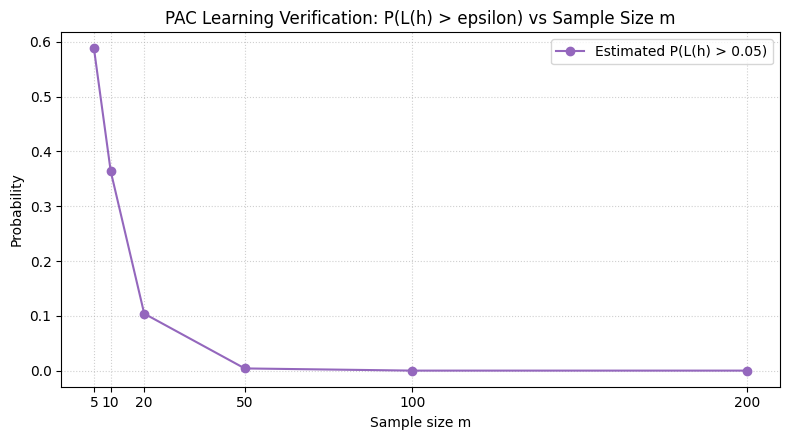

In [8]:
epsilon=0.05
n_repetitions=500

prob_bad_hypothesis=[]

for m in sample_sizes:
  bad_count=0
  for _ in range(n_repetitions):
    X_rep,y_rep=generate_data(m,theta=theta_true,noise_rate=0.0)
    t_opt,_=train_erm_threshold(X_rep,y_rep)
    true_err=np.abs(t_opt-theta_true)
    if true_err>epsilon:
      bad_count+=1
  prob_bad_hypothesis.append(bad_count/n_repetitions)

plt.figure(figsize=(8,4.5))
plt.plot(sample_sizes,prob_bad_hypothesis,marker='o',color='tab:purple',label=f'Estimated P(L(h) > {epsilon})')
plt.title('PAC Learning Verification: P(L(h) > epsilon) vs Sample Size m')
plt.xlabel('Sample size m')
plt.ylabel('Probability')
plt.xticks(sample_sizes)
plt.grid(True,linestyle=':',alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

### Experimental Verification of PAC Learning

*   For small training sizes ($m\le10$), the probability of failure $\mathbb{P}(L(h)>\epsilon)$ is significant ($\approx0.60$), reflecting insufficient sample coverage near the decision boundary.
*   As $m$ increases, this probability decays exponentially fast, dropping to approximately zero for $m\ge50$.
* This enpirically verifies the PAS learning guarantee: for any chosen accuracy $\epsilon>0$ and confidence $\delta>0$, there exists a sample complexity $m(\epsilon,\delta)$ such that $\mathbb{P}(L(h)\le\epsilon)\ge1-\delta$.

# 5 -From PAC to Agnostic PAC

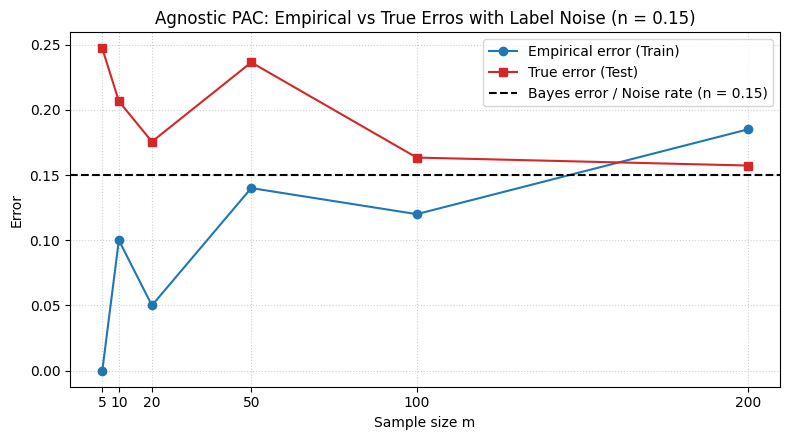

In [10]:
Noise_Rate=0.15
X_test_agnostic,y_test_agnostic=generate_data(n_test,theta=theta_true,noise_rate=Noise_Rate)

emp_errors_agnostic=[]
test_errors_agnostic=[]

for m in sample_sizes:
  X_train_n,y_train_n=generate_data(m,theta=theta_true,noise_rate=Noise_Rate)
  t_opt_n,emp_err_n=train_erm_threshold(X_train_n,y_train_n)
  test_err_n=compute_empirical_error(t_opt_n,X_test_agnostic,y_test_agnostic)
  emp_errors_agnostic.append(emp_err_n)
  test_errors_agnostic.append(test_err_n)

plt.figure(figsize=(8,4.5))
plt.plot(sample_sizes,emp_errors_agnostic,marker='o',label='Empirical error (Train)',color='tab:blue')
plt.plot(sample_sizes,test_errors_agnostic,marker='s',label='True error (Test)',color='tab:red')
plt.axhline(y=Noise_Rate,color='black',linestyle='--',label=f'Bayes error / Noise rate (n = {Noise_Rate})')
plt.title('Agnostic PAC: Empirical vs True Erros with Label Noise (n = 0.15)')
plt.xlabel('Sample size m')
plt.ylabel('Error')
plt.xticks(sample_sizes)
plt.grid(True,linestyle=':',alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

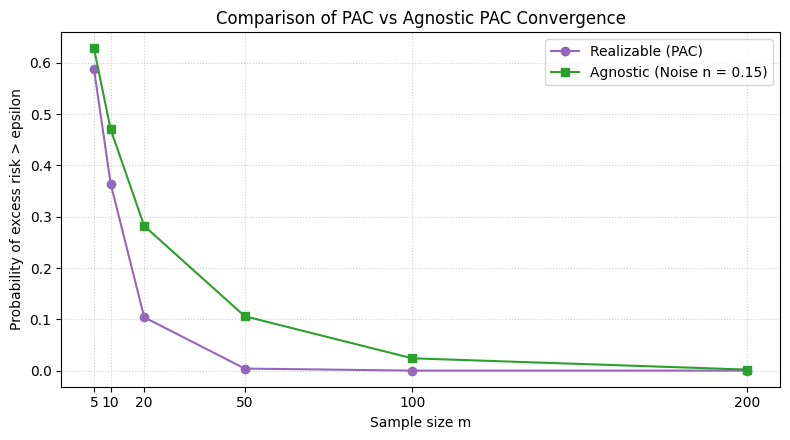

In [11]:
epsilon_agnostic=0.05
prob_bad_agnostic=[]

for m in sample_sizes:
  bad_count=0
  for _ in range(n_repetitions):
    X_rep,y_rep=generate_data(m,theta=theta_true,noise_rate=Noise_Rate)
    t_opt,_=train_erm_threshold(X_rep,y_rep)
    excess_risk=(1.0-2.0*Noise_Rate)*np.abs(t_opt-theta_true)
    if excess_risk>epsilon_agnostic:
      bad_count+=1
  prob_bad_agnostic.append(bad_count/n_repetitions)

plt.figure(figsize=(8,4.5))
plt.plot(sample_sizes,prob_bad_hypothesis,marker='o',label='Realizable (PAC)',color='tab:purple')
plt.plot(sample_sizes,prob_bad_agnostic,marker='s',label=f'Agnostic (Noise n = {Noise_Rate})',color='tab:green')
plt.title('Comparison of PAC vs Agnostic PAC Convergence')
plt.xlabel('Sample size m')
plt.ylabel('Probability of excess risk > epsilon')
plt.xticks(sample_sizes)
plt.grid(True,linestyle=':',alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

### Discussion: PAC vs Agnostic PAC Frameworks

#### 1. Can the empirical error still reach zero?
No, not in general. With independent label noise ($n=0.15$), two observations very close to each other can receive conflicting labels. Since a threshold classifier can only split the line into two monotonic regions, it cannot perfectly fit noisy labels once the sample size is large enough($m\ge10$). Consequently, the empirical error strictly exceeds zero and converges towards the noise level $n$.
#### 2. Does increasing the number of training examples still improve generalization performance?
Yes. Increasing $m$ narrows the generalization gap $|L(h)-L_S(h)|$ and causes the ERM threshold $t^*$ to converge toward the true target $\theta^*=0.5$. However, the generalization error $L(h)$ does not converge to zero; it converges toward the irreducible Bayes error $L^*=n=0.15$.
#### 3. Theoretical Connection to PAC and Agnostic PAC

*   Realizable PAC Setting: Assumes $f^*\in\mathcal{H}$ with deterministic labels ($L^*=0$). Sample complexity scales as $\mathcal{O}\left(\frac{1}{\epsilon}\ln\frac{1}{\delta}\right)$, yielding very fast exponential convergence.
*   Agnostic PAC Setting: Drops the realizability assumption and accommodates label noise. The learner guarantees that the excess risk $L(h)-\min_{h'\in\mathcal{H}}L(h')\le\epsilon$ with probability at least $1-\delta$. Because empirical frequencies of noisy observations must converge uniformly (via Hoeffding-type bounds), the agnostic sample complexity scales as $\mathcal{O}\left(\frac{1}{\epsilon^2}\ln\frac{1}{\delta}\right)$. This quadratic dependence on $1/\epsilon$ explains the slower rate of convergence observed in the final comparison plot.

## Conclusion

This experiment highlights the operational differences between PAC and Agnostic PAC learning:

1.   In the realizable setting, ERM achieves zero training error and the generalization error decays directly to zero at an exponential rate with respect to sample size.
2.   In the agnostic setting, the presence of label noise establishes and irreducible error floor (the Bayes error $n$). Increasing sample size cannot eliminate this intrinsic noise, but it guarantees uniform convergence of empirical risk to true risk, driving excess risk toward zero at a slower theoretical rate ($\mathcal{O}(1/\epsilon^2)$ vs $\mathcal{O}(1/\epsilon)$).